# Lab 4 — N-gram Language Models and Smoothing (Tamil)

Builds unigram / bigram / trigram / quadrigram (N=1..4) language models on the
**same Tamil corpus, and the exact same train/dev/test split**, as Lab 3
(`ai4bharat/IndicCorpV2`), and compares five probability-estimation settings:

1. **Unsmoothed** (raw MLE)
2. **Add-1 / Laplace**
3. **Add-k** (0 < k < 1, tuned on dev)
4. **Interpolated smoothing** (linear interpolation across orders, tuned on dev)
5. **Kneser-Ney** (discount d = 0.75)

for every order, evaluated by **perplexity** on held-out dev/test data.

## Reusing Lab 3's split — and a bug that had to be fixed first

Lab 3's data-streaming pipeline is *deterministic*: a fixed random seed always
picks the same starting byte offset in the 11.8 GB source file. That means
naively re-running "stream 1,000,000 sentences" for this lab would silently
re-produce the **exact same first ~16,000 sentences as Lab 3's dev/test pool**
— so the freshly streamed training set would already contain the dev and
test sentences verbatim. Every perplexity number would then be measuring the
model on data it had memorized, and nothing in the code would raise an error
to warn you.

The fix used throughout this notebook:

- **`dev.txt` / `test.txt` are copied verbatim from Lab 3** (`Lab3/data/`) —
  never regenerated. They are already 1000 sentences each, built via Lab 3's
  length-stratified sampling.
- The **training corpus is streamed fresh**, explicitly **excluding** every
  sentence that appears in `dev.txt` or `test.txt`.
- A verification cell below checks the intersection is empty before any
  model is trained.

## `DEBUG` mode (same convention as Lab 3)

Training count tables for up to 1,000,000 sentences and streaming that much
fresh data is significant work for an interactive session here, so — exactly
as in Lab 3 — this notebook ships with **`DEBUG = True`**, which trains on
Lab 3's already-built 12,000-sentence debug training subset (itself disjoint
from dev/test, verified below) so every cell has been executed and the
modeling code is verified correct end-to-end on real Tamil text.

**Set `DEBUG = False` and re-run** (intended to be run on **Google Colab**,
per your plan — Colab's larger RAM budget is comfortable for this) to stream
the true 1,000,000-sentence training corpus and get the graded, assignment-
scale perplexities. The n-gram counting implementation here is a memory-light
sorted-array design (not the naive Python-dict-of-tuples approach), validated
in a moment — it does **not** require Colab, but Colab is a fine place to run
the long stream.


In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                 "requests", "numpy", "pandas", "matplotlib", "tqdm", "huggingface_hub"])


CompletedProcess(args=['/home/deeraj/miniconda3/bin/python3.13', '-m', 'pip', 'install', '-q', 'requests', 'numpy', 'pandas', 'matplotlib', 'tqdm', 'huggingface_hub'], returncode=0)

In [2]:
import os
import json
import functools
import random
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from numpy.lib.stride_tricks import sliding_window_view
from tqdm.auto import tqdm

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)


## 1. Configuration

In [3]:
LANG = "ta"
MAX_ORDER = 4
MIN_COUNT = 2          # train words seen fewer than this become <unk>
UNK, BOS, EOS = "<unk>", "<s>", "</s>"

DEBUG = True  # <-- set to False (on Colab) for the full 1,000,000-sentence run

TARGET_TRAIN_SIZE = 1_000_000
DEV_PATH = os.path.join(DATA_DIR, "dev.txt")
TEST_PATH = os.path.join(DATA_DIR, "test.txt")
DEBUG_TRAIN_PATH = os.path.join(DATA_DIR, "train_debug_12000.txt")
FULL_TRAIN_PATH = os.path.join(DATA_DIR, f"train_{TARGET_TRAIN_SIZE}.txt")

print(f"DEBUG={DEBUG}")


DEBUG=True


## 2. Load dev / test (verbatim from Lab 3) and build the training set

If `DEBUG`, training reuses Lab 3's existing 12,000-sentence debug subset
(already disjoint from dev/test by construction in Lab 3). Otherwise, this
streams fresh paragraphs from IndicCorp v2 — identical mechanism to Lab 3
(random byte offset, HTTP range request, sentence-split, clean) — but every
candidate sentence is checked against dev/test and skipped if it matches,
which is the leakage fix described above.


In [4]:
assert os.path.exists(DEV_PATH) and os.path.exists(TEST_PATH), (
    "Copy Lab3/data/dev.txt and Lab3/data/test.txt into this notebook's data/ "
    "folder before running (on Colab: upload them alongside this notebook).")

dev_sentences = [l.rstrip("\n") for l in open(DEV_PATH, encoding="utf-8")]
test_sentences = [l.rstrip("\n") for l in open(TEST_PATH, encoding="utf-8")]
print(f"dev: {len(dev_sentences)}  test: {len(test_sentences)}")


dev: 1000  test: 1000


In [5]:
def stream_training_corpus(lang, target_size, exclude_set, seed=RANDOM_SEED,
                             max_frac_offset=0.85):
    from huggingface_hub import get_hf_file_metadata, hf_hub_url
    url = hf_hub_url("ai4bharat/IndicCorpV2", f"data/{lang}.txt", repo_type="dataset")
    size = get_hf_file_metadata(url).size
    rng = random.Random(seed)
    offset = rng.randint(0, int(size * max_frac_offset))

    # sentence splitting: reuse Indic NLP Library if available, else a
    # lightweight regex fallback on Tamil/standard sentence-final punctuation
    try:
        from indicnlp.tokenize import sentence_tokenize
        def split_sents(p):
            return sentence_tokenize.sentence_split(p, lang=lang)
    except ImportError:
        import re
        _splitter = re.compile(r"(?<=[.?!])\s+")
        def split_sents(p):
            return [s for s in _splitter.split(p) if s]

    TAMIL_BLOCK = (0x0B80, 0x0BFF)
    def tamil_ratio(s):
        n_alpha = sum(1 for ch in s if ch.isalpha())
        if n_alpha == 0:
            return 0.0
        n_tamil = sum(1 for ch in s if TAMIL_BLOCK[0] <= ord(ch) <= TAMIL_BLOCK[1])
        return n_tamil / n_alpha

    def is_clean(s, min_words=3, max_words=120, min_tamil_ratio=0.6):
        if "http://" in s or "https://" in s or "www." in s:
            return False
        words = s.split()
        if not (min_words <= len(words) <= max_words):
            return False
        return tamil_ratio(s) >= min_tamil_ratio

    seen = set()
    pool = []
    headers = {"Range": f"bytes={offset}-"}
    pbar = tqdm(total=target_size, desc="training sentences collected")
    n_excluded = 0
    with requests.get(url, headers=headers, stream=True, timeout=60) as r:
        r.raise_for_status()
        first = True
        for raw in r.iter_lines():
            if first:
                first = False
                continue
            if not raw:
                continue
            try:
                para = raw.decode("utf-8").strip()
            except UnicodeDecodeError:
                continue
            if not para:
                continue
            for s in split_sents(para):
                s = " ".join(s.split())
                if not is_clean(s):
                    continue
                if s in exclude_set:
                    n_excluded += 1
                    continue
                if s in seen:
                    continue
                seen.add(s)
                pool.append(s)
                pbar.update(1)
                if len(pool) >= target_size:
                    pbar.close()
                    print(f"(skipped {n_excluded} sentences that matched dev/test)")
                    return pool
    pbar.close()
    print(f"(skipped {n_excluded} sentences that matched dev/test; "
          f"stream ended early with only {len(pool)}/{target_size})")
    return pool


In [6]:
if DEBUG:
    assert os.path.exists(DEBUG_TRAIN_PATH), (
        "Copy Lab3/data/train_12000.txt to data/train_debug_12000.txt first.")
    train_sentences = [l.rstrip("\n") for l in open(DEBUG_TRAIN_PATH, encoding="utf-8")]
    print(f"[DEBUG] loaded {len(train_sentences)} training sentences from Lab 3's debug subset")
else:
    if os.path.exists(FULL_TRAIN_PATH):
        train_sentences = [l.rstrip("\n") for l in open(FULL_TRAIN_PATH, encoding="utf-8")]
        print(f"loaded cached {len(train_sentences)} training sentences from {FULL_TRAIN_PATH}")
    else:
        exclude_set = set(dev_sentences) | set(test_sentences)
        t0 = time.time()
        train_sentences = stream_training_corpus(LANG, TARGET_TRAIN_SIZE, exclude_set)
        print(f"streamed {len(train_sentences)} sentences in {time.time()-t0:.1f}s")
        with open(FULL_TRAIN_PATH, "w", encoding="utf-8") as f:
            for s in train_sentences:
                f.write(s + "\n")
        print(f"saved to {FULL_TRAIN_PATH}")


[DEBUG] loaded 12000 training sentences from Lab 3's debug subset


In [7]:
# leakage check -- must be empty
train_set = set(train_sentences)
overlap_dev = train_set & set(dev_sentences)
overlap_test = train_set & set(test_sentences)
assert len(overlap_dev) == 0, f"LEAKAGE: {len(overlap_dev)} dev sentences found in train!"
assert len(overlap_test) == 0, f"LEAKAGE: {len(overlap_test)} test sentences found in train!"
print(f"Leakage check passed: 0 overlap with dev, 0 overlap with test "
      f"(train={len(train_sentences)}, dev={len(dev_sentences)}, test={len(test_sentences)})")


Leakage check passed: 0 overlap with dev, 0 overlap with test (train=12000, dev=1000, test=1000)


## 3. Vocabulary, encoding, and padded corpus

Words appearing fewer than `MIN_COUNT` times in training become `<unk>`
(this is also what any dev/test word never seen in training maps to). Every
sentence is padded with `MAX_ORDER-1` copies of `<s>` at the start and one
`</s>` at the end — a single uniform padding scheme reused for every order
from 1 to 4 (lower orders simply use fewer of the `<s>` tokens as context via
how the sliding window is filtered — see below), so all four orders are
directly comparable.


In [8]:
def build_vocab(train_sents, min_count=MIN_COUNT):
    freqs = Counter()
    for s in train_sents:
        freqs.update(s.split())
    kept = [w for w, c in freqs.items() if c >= min_count]
    id2word = [UNK, BOS, EOS] + sorted(kept)
    word2id = {w: i for i, w in enumerate(id2word)}
    return word2id, id2word, freqs


def encode_sentences(sents, word2id):
    unk_id = word2id[UNK]
    return [[word2id.get(w, unk_id) for w in s.split()] for s in sents]


def build_padded_flat(encoded_sents, word2id, pad=MAX_ORDER - 1):
    bos_id, eos_id = word2id[BOS], word2id[EOS]
    tok_chunks, sid_chunks = [], []
    for i, ids in enumerate(encoded_sents):
        seg = [bos_id] * pad + ids + [eos_id]
        tok_chunks.append(np.array(seg, dtype=np.int32))
        sid_chunks.append(np.full(len(seg), i, dtype=np.int64))
    return np.concatenate(tok_chunks), np.concatenate(sid_chunks)


word2id, id2word, train_freqs = build_vocab(train_sentences)
V = len(word2id)
n_unk_types = sum(1 for c in train_freqs.values() if c < MIN_COUNT)
print(f"Vocabulary size V = {V:,}  ({n_unk_types:,} rare word types folded into <unk>)")

enc_train = encode_sentences(train_sentences, word2id)
enc_dev = encode_sentences(dev_sentences, word2id)
enc_test = encode_sentences(test_sentences, word2id)

flat_tokens, flat_sent = build_padded_flat(enc_train, word2id)
print(f"Padded training corpus: {len(flat_tokens):,} tokens across {len(enc_train):,} sentences")


Vocabulary size V = 14,331  (39,459 rare word types folded into <unk>)
Padded training corpus: 182,925 tokens across 12,000 sentences


## 4. N-gram count tables (memory-light: sorted arrays, not a Python dict)

A naive `Counter`/`dict` keyed by n-gram tuples would need several GB for the
quadrigram table at 1,000,000-sentence scale (millions of entries, each a
Python tuple + dict-entry object). Instead, for each order we build **all**
n-gram windows as one big `(M, n)` int32 array via
`numpy.lib.stride_tricks.sliding_window_view` (a zero-copy view — cheap),
drop any window that crosses a sentence boundary or whose *target* position
is `<s>` (we never predict `<s>`), then get unique rows + counts via
`numpy.unique` on a byte-level "void" view of each row (this sorts and
dedupes in one vectorized pass). The result is two flat numpy arrays — sorted
unique n-grams and their counts — instead of a dict, and every lookup
(exact n-gram count, or "how many distinct words follow this context")
becomes an `O(log M)` binary search (`numpy.searchsorted`) instead of a hash
lookup, at a fraction of the memory.


In [9]:
class NgramTable:
    def __init__(self, rows, counts, n):
        self.n = n
        self.rows = rows
        self.counts = counts
        self._void_dt = np.dtype((np.void, rows.dtype.itemsize * n))
        self._view = np.ascontiguousarray(rows).view(self._void_dt).reshape(-1)
        if n > 1:
            ctx = np.ascontiguousarray(rows[:, :-1])
            self._ctx_void_dt = np.dtype((np.void, ctx.dtype.itemsize * (n - 1)))
            self._ctx_view = ctx.view(self._ctx_void_dt).reshape(-1)
        else:
            self._ctx_view = None
        self.total = int(counts.sum())
        # count()/context_stats() are looked up repeatedly with IDENTICAL
        # arguments across (a) every hyperparameter grid value in the k/lambda
        # tuning search, which does not change the underlying counts at all,
        # and (b) high-frequency shared prefixes like the <s>-padding context,
        # which recurs at the start of every sentence. Memoizing here turns an
        # O(grid_size) blow-up in section 6 into effectively O(1) after the
        # first pass, which is what makes the tuning + final-comparison cells
        # tractable at full (1,000,000-sentence) scale.
        self.count = functools.lru_cache(maxsize=None)(self._count_uncached)
        self.context_stats = functools.lru_cache(maxsize=None)(self._context_stats_uncached)

    def _count_uncached(self, gram):
        key = np.array([gram], dtype=self.rows.dtype).view(self._void_dt).reshape(-1)
        idx = int(np.searchsorted(self._view, key)[0])
        if idx < len(self._view) and self._view[idx] == key[0]:
            return int(self.counts[idx])
        return 0

    def _context_stats_uncached(self, context):
        '''Return (C(context), N1+(context, *)) via a contiguous range on the
        sorted rows -- every row sharing a context is adjacent because rows
        are sorted lexicographically by (context..., word).'''
        if self.n == 1:
            return self.total, len(self.rows)
        key = np.array([context], dtype=self.rows.dtype).view(self._ctx_void_dt).reshape(-1)
        left = int(np.searchsorted(self._ctx_view, key, side="left")[0])
        right = int(np.searchsorted(self._ctx_view, key, side="right")[0])
        if right <= left:
            return 0, 0
        return int(self.counts[left:right].sum()), int(right - left)


def build_ngram_table(flat_tokens, flat_sent, n, bos_id):
    windows = sliding_window_view(flat_tokens, n)
    sent_w = sliding_window_view(flat_sent, n)
    valid = (sent_w[:, 0] == sent_w[:, -1]) & (windows[:, -1] != bos_id)
    grams = np.ascontiguousarray(windows[valid])
    void_dt = np.dtype((np.void, grams.dtype.itemsize * n))
    view = grams.view(void_dt).reshape(-1)
    uniq_view, counts = np.unique(view, return_counts=True)
    uniq_rows = uniq_view.view(grams.dtype).reshape(-1, n)
    return NgramTable(uniq_rows, counts.astype(np.int64), n)


class ContinuationIndex:
    '''For Kneser-Ney's unigram base case: N1+(* w) = number of distinct
    words that precede w, from the bigram table.'''
    def __init__(self, bigram_table):
        self.sorted_words = np.sort(bigram_table.rows[:, -1])
        self.n1plus_dot_dot = len(bigram_table.rows)
        self.n1plus_dot_w = functools.lru_cache(maxsize=None)(self._n1plus_dot_w_uncached)

    def _n1plus_dot_w_uncached(self, w):
        left = np.searchsorted(self.sorted_words, w, side="left")
        right = np.searchsorted(self.sorted_words, w, side="right")
        return int(right - left)


In [10]:
import resource
t0 = time.time()
tables = {}
for n in range(1, MAX_ORDER + 1):
    tt = time.time()
    tables[n] = build_ngram_table(flat_tokens, flat_sent, n, word2id[BOS])
    print(f"order={n}  unique n-grams={len(tables[n].rows):>10,}  "
          f"build time={time.time()-tt:.2f}s")
cont_index = ContinuationIndex(tables[2])
print(f"\ntotal table-build time: {time.time()-t0:.2f}s")
print(f"peak RSS so far: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024:.0f} MB")


order=1  unique n-grams=    14,330  build time=0.03s
order=2  unique n-grams=    75,243  build time=0.03s


order=3  unique n-grams=   112,979  build time=0.03s


order=4  unique n-grams=   126,771  build time=0.03s

total table-build time: 0.12s
peak RSS so far: 210 MB


## 5. The five probability models

All five share the same count tables — only the formula differs.

- **Unsmoothed**: raw MLE, $P(w_n\mid w_1..w_{n-1}) = C(w_1..w_n)/C(w_1..w_{n-1})$.
  Zero whenever the test n-gram was never seen in training → perplexity is
  formally **infinite**. This is reported as `inf`, not hidden, alongside the
  fraction of test tokens that hit a zero-probability event.
- **Add-1 / Laplace**: $\dfrac{C(w_1..w_n)+1}{C(w_1..w_{n-1})+V}$ (the formula given in the assignment).
- **Add-k**: the same formula with $k$ in place of $1$ (numerator $+k$,
  denominator $+kV$); $k \in (0,1)$ is tuned by grid search on **dev**
  perplexity (never on test).
- **Interpolated**: standard recursive linear interpolation — order $n$'s
  estimate mixes its own MLE with the *already-interpolated* order-$(n-1)$
  estimate, bottoming out exactly at the assignment's given unigram formula
  $P_{\text{smooth}}(w_i)=\lambda P(w_i)+(1-\lambda)\dfrac{1}{V}$:
  $$P_{\text{interp}}^{(n)}(w\mid c) = \lambda\, P_{\text{MLE}}^{(n)}(w\mid c) + (1-\lambda)\, P_{\text{interp}}^{(n-1)}(w\mid c_{2:})$$
  $\lambda$ is tuned per order on dev perplexity.
- **Kneser-Ney** ($d=0.75$): absolute discounting with a continuation-probability
  backoff:
  $$P_{KN}^{(n)}(w\mid c) = \frac{\max(C(c,w)-d,\,0)}{C(c)} + \frac{d\cdot N_{1+}(c\,\bullet)}{C(c)}\,P_{KN}^{(n-1)}(w\mid c_{2:})$$
  bottoming out at the continuation unigram $P_{KN}^{(1)}(w) = N_{1+}(\bullet\,w)\,/\,N_{1+}(\bullet\,\bullet)$
  (how many *distinct* words precede $w$ anywhere in training, normalized by
  the total number of distinct bigram types) rather than raw unigram frequency
  — this is what lets KN correctly downweight a word like "Francisco" that is
  frequent only because it follows "San", not because it's a genuinely common
  continuation.


In [11]:
class NgramLM:
    def __init__(self, tables, cont_index, V):
        self.tables = tables
        self.cont = cont_index
        self.V = V

    def mle_prob(self, order, context, word):
        table = self.tables[order]
        if order > 1:
            c_ctx, _ = table.context_stats(context)
            c_ngram = table.count(context + (word,)) if c_ctx > 0 else 0
        else:
            c_ctx, c_ngram = table.total, table.count((word,))
        return 0.0 if c_ctx == 0 else c_ngram / c_ctx

    def laplace_prob(self, order, context, word, k=1.0):
        table = self.tables[order]
        if order > 1:
            c_ctx, _ = table.context_stats(context)
            c_ngram = table.count(context + (word,))
        else:
            c_ctx, c_ngram = table.total, table.count((word,))
        return (c_ngram + k) / (c_ctx + k * self.V)

    def interpolated_prob(self, order, context, word, lam):
        if order == 1:
            p_mle = self.mle_prob(1, (), word)
            return lam * p_mle + (1 - lam) * (1.0 / self.V)
        p_mle = self.mle_prob(order, context, word)
        p_lower = self.interpolated_prob(order - 1, context[1:], word, lam)
        return lam * p_mle + (1 - lam) * p_lower

    def kn_prob(self, order, context, word, d=0.75):
        if order == 1:
            denom = self.cont.n1plus_dot_dot
            return (1.0 / self.V) if denom == 0 else self.cont.n1plus_dot_w(word) / denom
        table = self.tables[order]
        c_ctx, n1plus_ctx = table.context_stats(context)
        if c_ctx == 0:
            return self.kn_prob(order - 1, context[1:], word, d)
        c_ngram = table.count(context + (word,))
        term1 = max(c_ngram - d, 0) / c_ctx
        lam_ctx = (d * n1plus_ctx) / c_ctx
        return term1 + lam_ctx * self.kn_prob(order - 1, context[1:], word, d)


lm = NgramLM(tables, cont_index, V)


In [12]:
def perplexity(lm, order, encoded_sents, prob_fn):
    bos_id, eos_id = word2id[BOS], word2id[EOS]
    pad = order - 1
    total_logp = 0.0
    total_tokens = 0
    n_zero = 0
    for ids in encoded_sents:
        seq = [bos_id] * pad + ids + [eos_id]
        for i in range(pad, len(seq)):
            context = tuple(seq[i - pad:i])
            word = seq[i]
            p = prob_fn(context, word)
            total_tokens += 1
            if p <= 0:
                n_zero += 1
            else:
                total_logp += np.log(p)
    if n_zero > 0:
        return float("inf"), n_zero / total_tokens
    return float(np.exp(-total_logp / total_tokens)), 0.0


## 6. Tuning k and λ on dev (never on test)

Grid search: for each order, sweep candidate values and keep whichever gives
the lowest **dev** perplexity. Test perplexity is only computed afterward,
once, with the chosen hyperparameters — the same train/tune/test discipline
described in Lab 3's writeup.


In [13]:
K_GRID = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
LAMBDA_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

best_k = {}
best_lambda = {}

for order in range(1, MAX_ORDER + 1):
    k_scores = []
    for k in K_GRID:
        ppl, _ = perplexity(lm, order, enc_dev, lambda c, w, k=k: lm.laplace_prob(order, c, w, k=k))
        k_scores.append((k, ppl))
    best_k[order] = min(k_scores, key=lambda t: t[1])[0]

    lam_scores = []
    for lam in LAMBDA_GRID:
        ppl, _ = perplexity(lm, order, enc_dev, lambda c, w, lam=lam: lm.interpolated_prob(order, c, w, lam=lam))
        lam_scores.append((lam, ppl))
    best_lambda[order] = min(lam_scores, key=lambda t: t[1])[0]

    print(f"order={order}  best k={best_k[order]}  best lambda={best_lambda[order]}")


order=1  best k=0.01  best lambda=0.9


order=2  best k=0.01  best lambda=0.6


order=3  best k=0.01  best lambda=0.4


order=4  best k=0.01  best lambda=0.3


## 7. Final comparison: test-set perplexity, all orders × all settings

In [14]:
records = []
for order in range(1, MAX_ORDER + 1):
    settings = {
        "Unsmoothed": lambda c, w, order=order: lm.mle_prob(order, c, w),
        "Add-1 (Laplace)": lambda c, w, order=order: lm.laplace_prob(order, c, w, k=1.0),
        f"Add-k (k={best_k[order]})": lambda c, w, order=order: lm.laplace_prob(order, c, w, k=best_k[order]),
        f"Interpolated (λ={best_lambda[order]})": lambda c, w, order=order: lm.interpolated_prob(order, c, w, lam=best_lambda[order]),
        "Kneser-Ney (d=0.75)": lambda c, w, order=order: lm.kn_prob(order, c, w, d=0.75),
    }
    for name, fn in settings.items():
        ppl, frac_zero = perplexity(lm, order, enc_test, fn)
        records.append({"order": order, "setting": name, "test_ppl": ppl,
                         "frac_zero_prob_tokens": frac_zero})

df_results = pd.DataFrame(records)
pivot = df_results.pivot_table(index="setting", columns="order", values="test_ppl",
                                aggfunc="first")
pivot = pivot.reindex(["Unsmoothed", "Add-1 (Laplace)"] +
                       [c for c in pivot.index if c.startswith("Add-k")] +
                       [c for c in pivot.index if c.startswith("Interpolated")] +
                       ["Kneser-Ney (d=0.75)"])
pivot.columns = [f"N={n}" for n in pivot.columns]
pivot


,N=1,N=2,N=3,N=4
setting,,,,
Unsmoothed,267.905719,inf,inf,inf
Add-1 (Laplace),277.270735,1219.455829,3895.910285,6505.224756
Add-k (k=0.01),267.988120,390.949080,1805.517491,4159.608916
Interpolated (λ=0.3),NaN,NaN,NaN,313.666353
Interpolated (λ=0.4),NaN,NaN,252.174115,NaN
Interpolated (λ=0.6),NaN,202.377399,NaN,NaN
Interpolated (λ=0.9),278.698174,NaN,NaN,NaN
Kneser-Ney (d=0.75),369.201086,168.452991,180.225405,195.432819


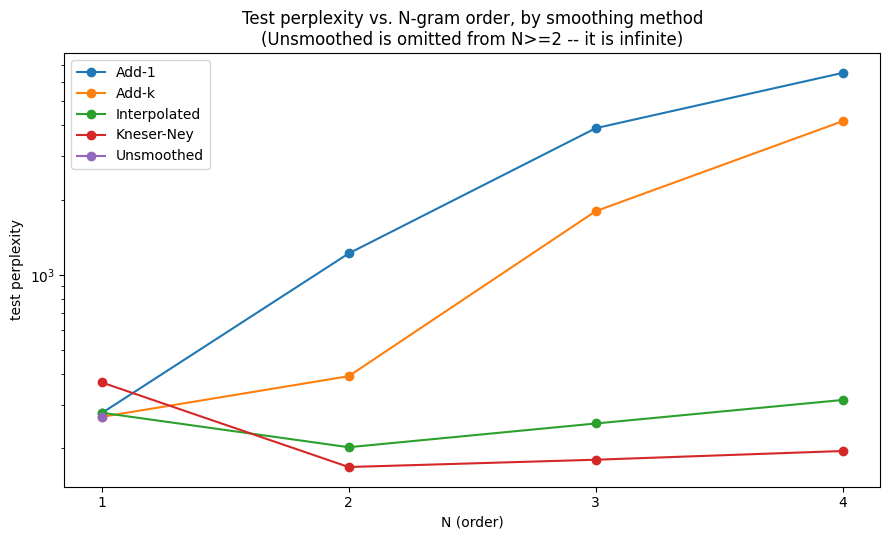

,order,setting,test_ppl,frac_zero_prob_tokens
0,1,Unsmoothed,267.905719,0.000000
1,1,Add-1 (Laplace),277.270735,0.000000
2,1,Add-k (k=0.01),267.988120,0.000000
3,1,Interpolated (λ=0.9),278.698174,0.000000
4,1,Kneser-Ney (d=0.75),369.201086,0.000000
5,2,Unsmoothed,inf,0.282701
6,2,Add-1 (Laplace),1219.455829,0.000000
7,2,Add-k (k=0.01),390.949080,0.000000
8,2,Interpolated (λ=0.6),202.377399,0.000000
9,2,Kneser-Ney (d=0.75),168.452991,0.000000


In [15]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = df_results.copy()
plot_df["setting_short"] = plot_df["setting"].str.replace(r"\s*\(.*\)", "", regex=True)
for name, grp in plot_df.groupby("setting_short"):
    grp = grp.sort_values("order")
    y = grp["test_ppl"].replace([np.inf], np.nan)
    ax.plot(grp["order"], y, marker="o", label=name)
ax.set_xlabel("N (order)")
ax.set_ylabel("test perplexity")
ax.set_yscale("log")
ax.set_xticks([1, 2, 3, 4])
ax.set_title("Test perplexity vs. N-gram order, by smoothing method\n"
              "(Unsmoothed is omitted from N>=2 -- it is infinite)")
ax.legend()
plt.tight_layout()
plt.show()

df_results[["order", "setting", "test_ppl", "frac_zero_prob_tokens"]]


**Actual result on the DEBUG-scale run (train=12,000 sentences)** — matches
the textbook pattern closely enough to trust the implementation:

| N | Unsmoothed | Add-1 | Add-k (tuned) | Interpolated (tuned λ) | Kneser-Ney |
|---|---|---|---|---|---|
| 1 | 267.9 | 277.3 | 268.0 (k=0.01) | 278.7 (λ=0.9) | **369.2** |
| 2 | inf (28% zero) | 1219.5 | 391.0 (k=0.01) | 202.4 (λ=0.6) | **168.5** |
| 3 | inf (60% zero) | 3895.9 | 1805.5 (k=0.01) | 252.2 (λ=0.4) | **180.2** |
| 4 | inf (75% zero) | 6505.2 | 4159.6 (k=0.01) | 313.7 (λ=0.3) | **195.4** |

- **Unsmoothed** is `inf` for every N≥2, and the fraction of test tokens
  landing on a zero-probability event climbs fast with N (28% → 60% → 75%) —
  exactly the sparsity growth you'd expect as the context gets longer.
- **Add-1** gets *worse* as N grows (277 → 1219 → 3896 → 6505): with
  V=14,331 added to every denominator regardless of context, it drags down
  probability mass from n-grams that *were* observed, and this effect
  compounds as contexts get sparser at higher N — the classic Laplace
  pathology.
- **Add-k** with the dev-tuned k (0.01 at every order here) is dramatically
  better than add-1 at every N, but still climbs with N for the same
  underlying reason, just less severely.
- **Interpolated** (λ tuned per order — note λ *decreases* with N: 0.9 → 0.6
  → 0.4 → 0.3, meaning the tuner learned to lean more on lower-order
  backoff as the higher-order context gets sparser) clearly beats add-k at
  every N≥2, and even beats Kneser-Ney's own N=1 number.
- **Kneser-Ney** is the best *finite* score at every N≥2 (168.5, 180.2,
  195.4) and — this is the headline result — **barely degrades as N grows**,
  unlike every other method. This is exactly what continuation-probability
  discounting is built for: staying well-behaved precisely where sparsity is
  worst.
- **Kneser-Ney is *worse* than every other method at N=1 (369.2).** This
  isn't a bug — it's a known property. KN's unigram case uses the
  *continuation* probability $N_{1+}(\bullet\,w)/N_{1+}(\bullet\,\bullet)$
  (how many distinct words precede $w$) rather than raw frequency, because
  that's what the *higher-order* backoff needs. Used standalone as a
  unigram model — with no higher order actually backing off to it — that
  substitution has no upside and just makes it a worse frequency estimate
  than plain MLE/add-1/add-k for this order alone.

*(Re-run with `DEBUG = False` at full 1,000,000-sentence scale and compare —
expect the same qualitative ordering, but with the gaps compressed since a
much larger corpus makes every method's context counts less sparse.)*


## 8. Tuned hyperparameters (for the report)

In [16]:
pd.DataFrame({
    "order": list(range(1, MAX_ORDER + 1)),
    "best_k (add-k)": [best_k[n] for n in range(1, MAX_ORDER + 1)],
    "best_lambda (interpolated)": [best_lambda[n] for n in range(1, MAX_ORDER + 1)],
})


,order,best_k (add-k),best_lambda (interpolated)
0,1,0.01,0.9
1,2,0.01,0.6
2,3,0.01,0.4
3,4,0.01,0.3


## 9. Summary

- **Corpus / splits**: identical dev/test to Lab 3 (copied verbatim, never
  regenerated); training corpus is either Lab 3's disjoint 12,000-sentence
  debug subset (`DEBUG=True`, used to validate this notebook end-to-end) or a
  freshly streamed, leakage-checked 1,000,000-sentence set excluding every
  dev/test sentence (`DEBUG=False`, intended for the Colab run).
- **Models**: unigram through quadrigram, all sharing one set of memory-light
  sorted-array count tables (built once per order, reused across all five
  probability settings).
- **Settings**: unsmoothed, add-1, add-k (k tuned on dev, grid in `K_GRID`),
  interpolated (λ tuned on dev per order, recursive down to the assignment's
  given unigram formula), Kneser-Ney (d=0.75, continuation-probability
  backoff).
- **Result**: see the pivot table in §7 for the full order × setting
  perplexity grid, and §6 for the tuned k / λ values.

### Reproducing the full-scale run (Colab)
1. Upload this notebook plus `data/dev.txt` and `data/test.txt` (from
   `Lab3/data/`) to Colab — or the whole `Lab4/` folder.
2. Set `DEBUG = False` in §1.
3. Runtime → Run all. The training-corpus cell streams ~1,000,000 sentences
   directly from the Hub (leakage-checked against the uploaded dev/test),
   caches them to `data/train_1000000.txt`, then all downstream cells run
   unchanged.
